In [1]:
print("hello world")

hello world


HANDS ON DAY 1

1. Import library 2 python yang sudah diinstall di terminal

In [2]:
import pandas as pd
import numpy as np
import geopandas as gpd
import folium
import seaborn as sns
from shapely.geometry import Point, Polygon, LineString
import matplotlib.pyplot as plt


2.Load Data GeoJSON

In [3]:
# Load the GeoJSON file
gdf = gpd.read_file("data_dummy_hidrokarbon.geojson")

# Display the first few rows
print(gdf.head())

     wilayah  potensi_hidrokarbon  kedalaman jenis_batuan  porositas  \
0    Cirebon                  120       2500    Sandstone         18   
1     Bekasi                  200       3200    Limestone         22   
2   Karawang                  150       2800        Shale         15   
3     Subang                   80       2100    Sandstone         20   
4  Indramayu                  170       3000        Shale         17   

   permeabilitas kecamatan                                           geometry  
0            120    Kec. A  POLYGON ((108.5 -6.7, 108.6 -6.7, 108.6 -6.6, ...  
1            210    Kec. B  POLYGON ((107 -6.3, 107.1 -6.3, 107.1 -6.2, 10...  
2             90    Kec. C  POLYGON ((107.3 -6.2, 107.4 -6.2, 107.4 -6.1, ...  
3            160    Kec. D  POLYGON ((107.7 -6.5, 107.8 -6.5, 107.8 -6.4, ...  
4            130    Kec. E  POLYGON ((108 -6.4, 108.1 -6.4, 108.1 -6.3, 10...  


3. Mengambil data yang dibutuhkan

In [4]:
hidrokarbon_path = "data_dummy_hidrokarbon.geojson"

4. Tampilkan sebagai dataframe dari data source hidrokarbon

In [5]:
gdf_hidrokarbon = gpd.read_file(hidrokarbon_path)

print(gdf_hidrokarbon.head())

     wilayah  potensi_hidrokarbon  kedalaman jenis_batuan  porositas  \
0    Cirebon                  120       2500    Sandstone         18   
1     Bekasi                  200       3200    Limestone         22   
2   Karawang                  150       2800        Shale         15   
3     Subang                   80       2100    Sandstone         20   
4  Indramayu                  170       3000        Shale         17   

   permeabilitas kecamatan                                           geometry  
0            120    Kec. A  POLYGON ((108.5 -6.7, 108.6 -6.7, 108.6 -6.6, ...  
1            210    Kec. B  POLYGON ((107 -6.3, 107.1 -6.3, 107.1 -6.2, 10...  
2             90    Kec. C  POLYGON ((107.3 -6.2, 107.4 -6.2, 107.4 -6.1, ...  
3            160    Kec. D  POLYGON ((107.7 -6.5, 107.8 -6.5, 107.8 -6.4, ...  
4            130    Kec. E  POLYGON ((108 -6.4, 108.1 -6.4, 108.1 -6.3, 10...  


5. Menentukan titik tengah (centroid) dari data source yang ada

In [6]:
gdf_hidrokarbon['centroid'] = gdf_hidrokarbon.geometry.centroid
gdf_hidrokarbon['longitude'] = gdf_hidrokarbon['centroid'].x
gdf_hidrokarbon['latitude'] = gdf_hidrokarbon['centroid'].y
# DataFrame dengan semua kolom + centroid
gdf_hidrokarbon = gdf_hidrokarbon.copy()
print(gdf_hidrokarbon)

      wilayah  potensi_hidrokarbon  kedalaman jenis_batuan  porositas  \
0     Cirebon                  120       2500    Sandstone         18   
1      Bekasi                  200       3200    Limestone         22   
2    Karawang                  150       2800        Shale         15   
3      Subang                   80       2100    Sandstone         20   
4   Indramayu                  170       3000        Shale         17   
5  Purwakarta                  110       2600    Limestone         19   
6  Majalengka                   95       2400    Sandstone         16   
7    Sumedang                  130       2700        Shale         21   
8     Bandung                   60       1800    Limestone         14   
9       Garut                   75       2200    Sandstone         18   

   permeabilitas kecamatan                                           geometry  \
0            120    Kec. A  POLYGON ((108.5 -6.7, 108.6 -6.7, 108.6 -6.6, ...   
1            210    Kec. B  POLYGO

C:\Users\ASUS\AppData\Local\Temp\ipykernel_2552\748013497.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf_hidrokarbon['centroid'] = gdf_hidrokarbon.geometry.centroid


6.

In [7]:
# Statistik deskriptif seluruh parameter numerik
print("Statistik Deskriptif:")
print(gdf_hidrokarbon.describe())

Statistik Deskriptif:
       potensi_hidrokarbon    kedalaman  porositas  permeabilitas   longitude  \
count            10.000000    10.000000  10.000000      10.000000   10.000000   
mean            119.000000  2530.000000  18.000000     125.500000  107.740000   
std              44.522154   424.394994   2.581989      37.892391    0.477144   
min              60.000000  1800.000000  14.000000      80.000000  107.050000   
25%              83.750000  2250.000000  16.250000     102.500000  107.400000   
50%             115.000000  2550.000000  18.000000     117.500000  107.700000   
75%             145.000000  2775.000000  19.750000     137.500000  108.000000   
max             200.000000  3200.000000  22.000000     210.000000  108.550000   

        latitude  
count  10.000000  
mean   -6.560000  
std     0.268535  
min    -6.950000  
25%    -6.750000  
50%    -6.550000  
75%    -6.375000  
max    -6.150000  


7. Analisa statistik histogram data hidrokarbon

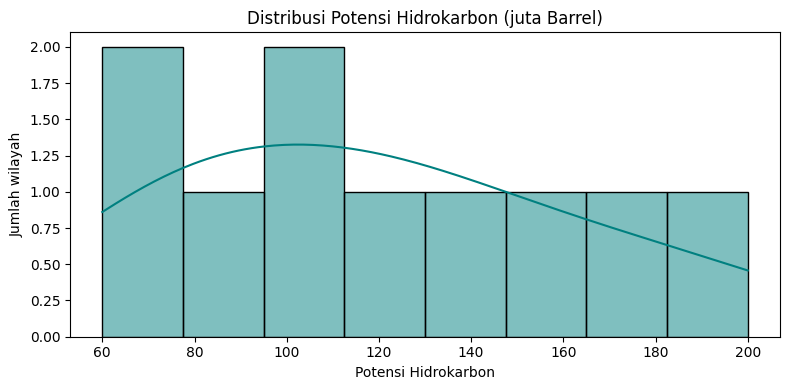

In [8]:
plt.figure(figsize=(8,4))
sns.histplot(gdf_hidrokarbon['potensi_hidrokarbon'], bins=8, kde=True, color='teal')
plt.title('Distribusi Potensi Hidrokarbon (juta Barrel)')
plt.xlabel('Potensi Hidrokarbon')
plt.ylabel('Jumlah wilayah')
plt.tight_layout()
plt.show()

8. Membuat boxplot perbandingan hubungan batu reservoir dengan potnesi hidrokarbon

C:\Users\ASUS\AppData\Local\Temp\ipykernel_2552\3619127291.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='jenis_batuan', y='potensi_hidrokarbon', data=gdf_hidrokarbon, palette='Set2')


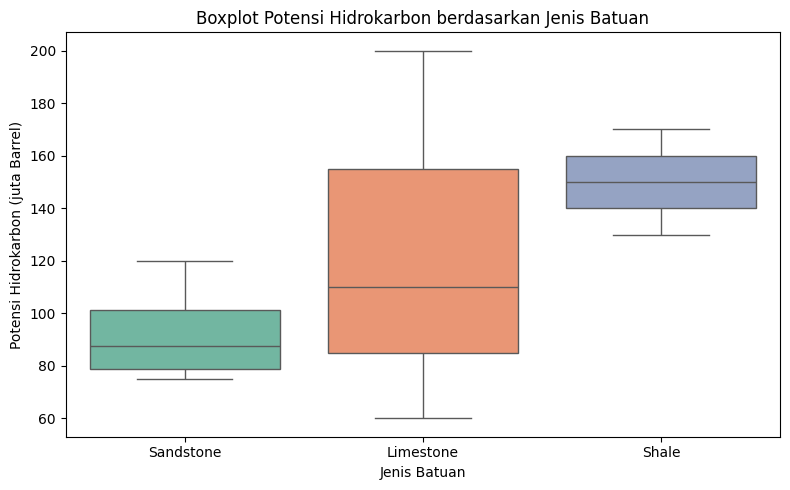

In [9]:
plt.figure(figsize=(8,5))
sns.boxplot(x='jenis_batuan', y='potensi_hidrokarbon', data=gdf_hidrokarbon, palette='Set2')
plt.title('Boxplot Potensi Hidrokarbon berdasarkan Jenis Batuan')
plt.xlabel('Jenis Batuan')
plt.ylabel('Potensi Hidrokarbon (juta Barrel)')
plt.tight_layout()
plt.show()

9. Membuat scatter plot hubungan antara potensi hidrokarbon dengan kedalaman dan porositas serta jenis batuan reservoir

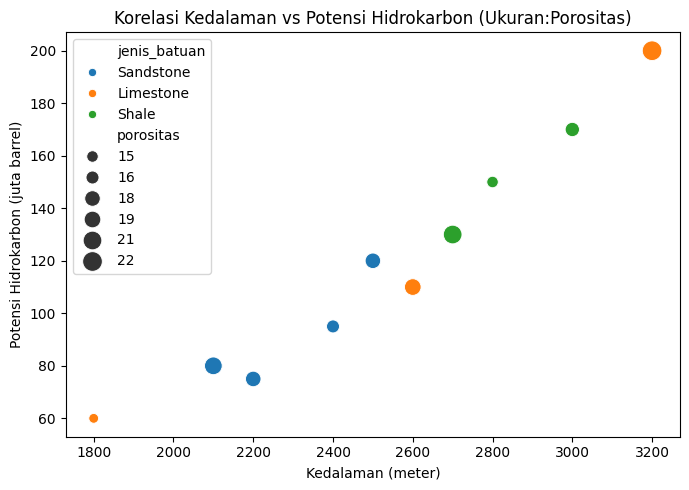

In [10]:
plt.figure(figsize=(7,5))
sns.scatterplot( x='kedalaman', y='potensi_hidrokarbon', data=gdf_hidrokarbon, hue='jenis_batuan', size='porositas',sizes=(50, 200), palette='tab10')
plt.title('Korelasi Kedalaman vs Potensi Hidrokarbon (Ukuran:Porositas)')
plt.xlabel('Kedalaman (meter)')
plt.ylabel('Potensi Hidrokarbon (juta barrel)')
plt.tight_layout()
plt.show()

10. Heatmap Korelasi Antar Parameter Reservoir Heatmap

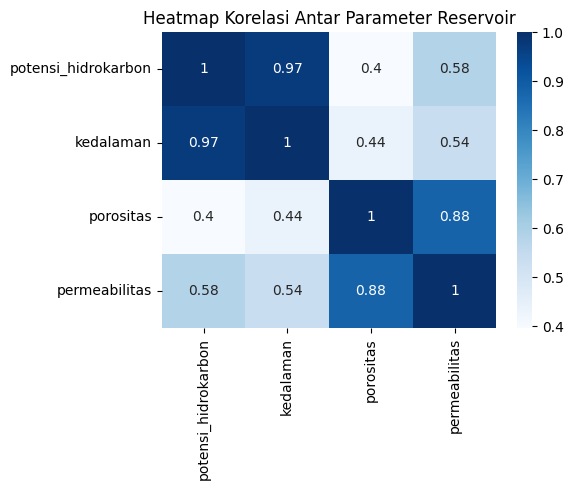

In [11]:
corr_matrix = gdf_hidrokarbon[['potensi_hidrokarbon', 'kedalaman',
'porositas', 'permeabilitas']].corr()
plt.figure(figsize=(6,5))
sns.heatmap(corr_matrix, annot=True, cmap='Blues')
plt.title('Heatmap Korelasi Antar Parameter Reservoir')
plt.tight_layout()
plt.show()

11. membuat peta statis sebaran hidrokarbon jawa barat

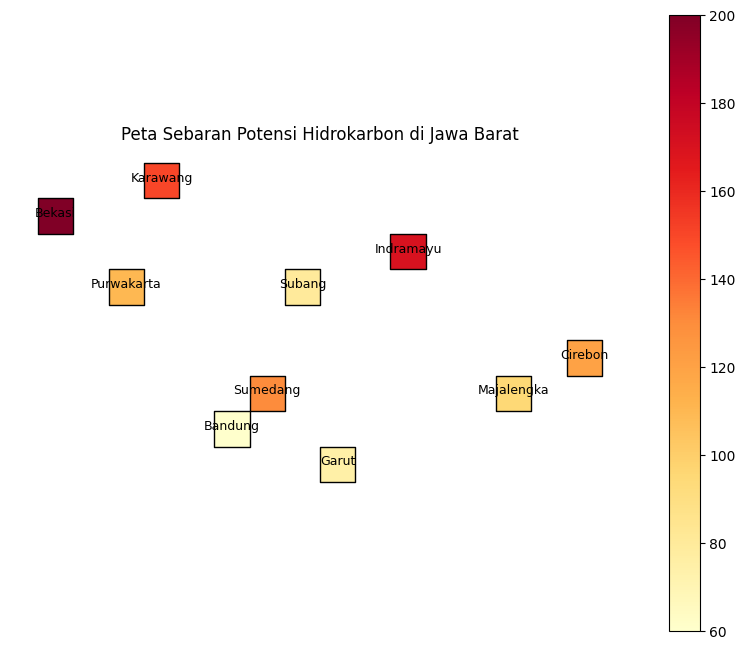

In [12]:
fig, ax = plt.subplots(figsize=(10,8))
gdf_hidrokarbon.plot(column='potensi_hidrokarbon', ax=ax, legend=True, cmap='YlOrRd',edgecolor='black')
for idx, row in gdf_hidrokarbon.iterrows():
    ax.annotate(
        text=row['wilayah'],
                 xy=(row['longitude'], row['latitude']),
                 ha='center',
                 fontsize=9,
                 color='black')
plt.title('Peta Sebaran Potensi Hidrokarbon di Jawa Barat')
plt.axis('off')
plt.show()

12. Cluster Potensi Hidrokarbon Wilayah

In [13]:
def cluster_potensi(val):
 if val > 150: return 'Tinggi'
 elif val >= 100: return 'Sedang'
 else: return 'Rendah'
gdf_hidrokarbon['cluster_potensi'] = gdf_hidrokarbon['potensi_hidrokarbon'].apply(cluster_potensi)
print(gdf_hidrokarbon[['wilayah', 'potensi_hidrokarbon',
'cluster_potensi']])

      wilayah  potensi_hidrokarbon cluster_potensi
0     Cirebon                  120          Sedang
1      Bekasi                  200          Tinggi
2    Karawang                  150          Sedang
3      Subang                   80          Rendah
4   Indramayu                  170          Tinggi
5  Purwakarta                  110          Sedang
6  Majalengka                   95          Rendah
7    Sumedang                  130          Sedang
8     Bandung                   60          Rendah
9       Garut                   75          Rendah


13. Visualisasi Cluster Potensi Bar

C:\Users\ASUS\AppData\Local\Temp\ipykernel_2552\2530989398.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='cluster_potensi', data=gdf_hidrokarbon,


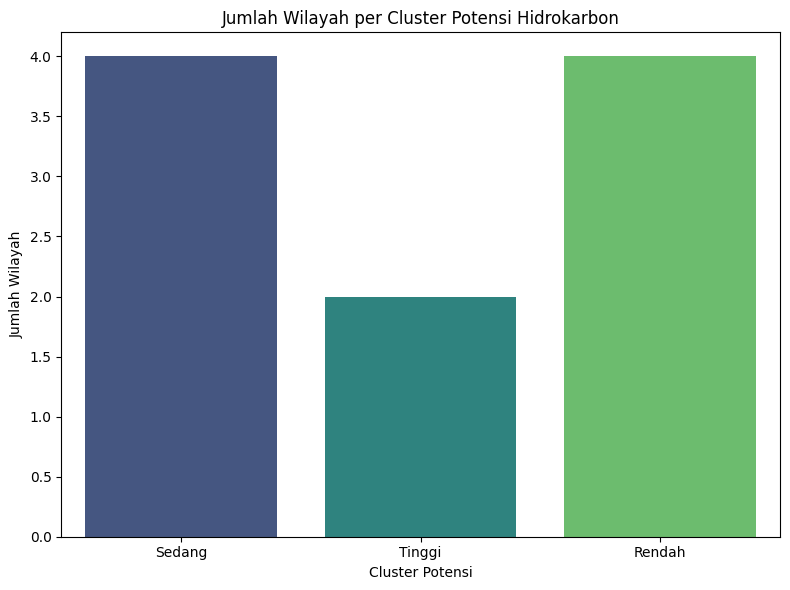

In [14]:
plt.figure(figsize=(8,6))
sns.countplot(x='cluster_potensi', data=gdf_hidrokarbon,
palette='viridis')
plt.title('Jumlah Wilayah per Cluster Potensi Hidrokarbon')
plt.xlabel('Cluster Potensi')
plt.ylabel('Jumlah Wilayah')
plt.tight_layout()
plt.show()